# 02 · Clasificación con árbol de decisión

**Responsable:** Ignacio González

**Pregunta:** ¿un día va a ser de alta demanda de viajes para una estación y un tipo de residuo?

**Datos:** `data/processed/datos_limpios.csv`, generado en `01_preparacion.ipynb`.

In [1]:
# Paso 1 · Librerías

import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn: la librería de aprendizaje automático.
# DecisionTreeClassifier es el árbol de decisión para clasificar;
# plot_tree lo dibuja (lo usamos al final para leer sus reglas)
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Métricas para evaluar el modelo (las usamos en la Etapa 4)
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

In [2]:
# Paso 2 · Cargar los datos limpios

# parse_dates convierte "fecha" a tipo fecha al leer (en el CSV se guarda como texto)
df = pd.read_csv("../data/processed/datos_limpios.csv", parse_dates=["fecha"])

print(df.shape)
df.head()

(12330, 12)


,fecha,estacion,tipo,toneladas,viajes,anio,mes,dia_semana,feriado,sin_recoleccion,toneladas_sem_ant,viajes_sem_ant
0,2017-01-09,Norte,Basura,99.340123,30,2017,1,Lunes,0,0,70.523624,23
1,2017-01-09,Norte,Organicos,27.591310,7,2017,1,Lunes,0,0,23.750000,7
2,2017-01-09,Sur,Basura,325.610668,99,2017,1,Lunes,0,0,364.491521,111
3,2017-01-09,Sur,Organicos,211.350862,49,2017,1,Lunes,0,0,233.762208,48
4,2017-01-09,Sur,Reciclables,402.682309,85,2017,1,Lunes,0,0,402.273225,93


In [3]:
# Paso 3 · Variables de entrada

# Qué hacemos: definir qué columnas puede usar el modelo para predecir.

# Por qué: es acá donde se aplica la regla contra la fuga de información.
# Si se escribe la lista explícitamente, queda claro qué se usa y qué no,
# y nadie puede usar 'viajes' por error.

# Lista explícita de entradas permitidas.
# NO están 'viajes' ni 'toneladas' del mismo día: 'viajes' define la categoría
# que queremos predecir, y 'toneladas' está casi perfectamente relacionada con ella
# (correlación de 0,95). Usarlas sería darle la respuesta al modelo.
entradas = [
    "estacion", "tipo", "dia_semana",             # categóricas (texto)
    "anio", "mes", "feriado", "sin_recoleccion",  # de calendario (números)
    "toneladas_sem_ant", "viajes_sem_ant",        # semana anterior: ya ocurrieron, son válidas
]

df[entradas].head()

,estacion,tipo,dia_semana,anio,mes,feriado,sin_recoleccion,toneladas_sem_ant,viajes_sem_ant
0,Norte,Basura,Lunes,2017,1,0,0,70.523624,23
1,Norte,Organicos,Lunes,2017,1,0,0,23.750000,7
2,Sur,Basura,Lunes,2017,1,0,0,364.491521,111
3,Sur,Organicos,Lunes,2017,1,0,0,233.762208,48
4,Sur,Reciclables,Lunes,2017,1,0,0,402.273225,93


**Variables de entrada:** estación, tipo de residuo, día de la semana, año, mes, feriado, día sin recolección (`sin_recoleccion`) y los valores de la semana anterior.

Se excluyen `viajes` y `toneladas` del mismo día porque revelarían la respuesta: la categoría se construye con los viajes, y las toneladas tienen una correlación de 0,95 con ellos.

In [4]:
# Paso 4 · Codificación one-hot

# Qué hacemos: transformar las columnas de texto (estación, tipo, día) en columnas de 0 y 1.

# Por qué: scikit-learn solo trabaja con números.
# No podemos reemplazar “Norte” por 1 y “Sur” por 2, porque el modelo interpretaría que Sur es “más” que Norte, y eso no significa nada.
# La solución se llama codificación one-hot: una columna por cada valor posible, con 1 si la fila tiene ese valor y 0 si no.

# get_dummies crea una columna de 0 y 1 por cada valor de las columnas indicadas.
# Las columnas numéricas (anio, mes, feriado, sin_recoleccion, semana anterior) quedan como están.
# dtype=int hace que los valores sean 0 y 1 (si no, serían True y False)
X = pd.get_dummies(
    df[entradas],
    columns=["estacion", "tipo", "dia_semana"],
    dtype=int,
)

print(X.shape)
print(X.columns.tolist())
X.head()

(12330, 16)
['anio', 'mes', 'feriado', 'sin_recoleccion', 'toneladas_sem_ant', 'viajes_sem_ant', 'estacion_Norte', 'estacion_Sur', 'tipo_Basura', 'tipo_Organicos', 'tipo_Reciclables', 'dia_semana_Jueves', 'dia_semana_Lunes', 'dia_semana_Martes', 'dia_semana_Miercoles', 'dia_semana_Viernes']


,anio,mes,feriado,sin_recoleccion,toneladas_sem_ant,viajes_sem_ant,estacion_Norte,estacion_Sur,tipo_Basura,tipo_Organicos,tipo_Reciclables,dia_semana_Jueves,dia_semana_Lunes,dia_semana_Martes,dia_semana_Miercoles,dia_semana_Viernes
0,2017,1,0,0,70.523624,23,1,0,1,0,0,0,1,0,0,0
1,2017,1,0,0,23.750000,7,1,0,0,1,0,0,1,0,0,0
2,2017,1,0,0,364.491521,111,0,1,1,0,0,0,1,0,0,0
3,2017,1,0,0,233.762208,48,0,1,0,1,0,0,1,0,0,0
4,2017,1,0,0,402.273225,93,0,1,0,0,1,0,1,0,0,0


**Codificación one-hot:** las variables categóricas se transformaron en columnas de 0 y 1, una por cada valor posible. No se usaron números consecutivos (Norte = 1, Sur = 2) porque el modelo interpretaría un orden que no existe.

| `estacion` | → | `estacion_Norte` | `estacion_Sur` |
| --- | --- | --- | --- |
| Norte | | 1 | 0 |
| Sur | | 0 | 1 |

Las 9 variables de entrada se convierten en 16 columnas: 6 numéricas, 2 de estación, 3 de tipo de residuo y 5 de día de la semana.

In [5]:
# Paso 5 · División en entrenamiento y prueba

# Qué hacemos: separar los datos con los que el árbol aprende de los datos con los que lo evaluamos.

# Por qué por fecha y no al azar: queremos predecir días futuros. Si mezcláramos al azar,
# el modelo aprendería con días de 2026 y se evaluaría con días de 2020: estaría "viendo
# el futuro" y las métricas mentirían.

# Fecha de corte acordada con Lázaro (la misma en los dos notebooks).
# Todo lo anterior entrena; todo lo posterior evalúa.
FECHA_CORTE = "2024-12-01"

# Máscara: True en las filas de entrenamiento, False en las de prueba.
# Se calcula una sola vez y se usa para separar todo lo demás,
# así X, y y df quedan siempre alineados fila por fila
es_entrenamiento = df["fecha"] < FECHA_CORTE

print("Entrenamiento:", es_entrenamiento.sum(), "filas,",
      df.loc[es_entrenamiento, "fecha"].min().date(), "a", df.loc[es_entrenamiento, "fecha"].max().date())
print("Prueba:       ", (~es_entrenamiento).sum(), "filas,",
      df.loc[~es_entrenamiento, "fecha"].min().date(), "a", df.loc[~es_entrenamiento, "fecha"].max().date())
print(f"Proporción de prueba: {(~es_entrenamiento).mean():.1%}")

Entrenamiento: 10072 filas, 2017-01-09 a 2024-11-29
Prueba:        2258 filas, 2024-12-02 a 2026-09-04
Proporción de prueba: 18.3%


**División:** se entrena con los días anteriores al 1/12/2024 y se evalúa con los posteriores, respetando el orden temporal, porque el objetivo es predecir días futuros. Es la misma fecha de corte que usa el modelo de regresión.

Se usa una máscara (`es_entrenamiento`) en lugar de dos tablas separadas: con la misma máscara se separan después las entradas (`X`) y la respuesta (`y`), así no pueden quedar desalineadas.

In [6]:
# Paso 6 · Categoría de alta demanda

# Qué hacemos: marcar cada día con 1 (alta demanda) o 0 (normal), según si sus viajes
# superan la mediana de su estación y tipo de residuo.

# Por qué un umbral por estación y tipo: la estación Sur recibe varias veces más viajes que la Norte.
# Con un umbral único, la Sur sería siempre "alta" y la Norte siempre "normal".
# Por qué solo con entrenamiento: si usáramos todos los datos, el umbral contendría
# información del período de prueba (sería "mirar el futuro").

# Mediana de viajes por estación y tipo, calculada SOLO con entrenamiento
umbrales = (df[es_entrenamiento]
            .groupby(["estacion", "tipo"])["viajes"]
            .median()
            .rename("umbral_viajes"))
print(umbrales)

# join pega a cada fila el umbral de su estación y tipo,
# sin cambiar el orden ni la numeración de las filas
df = df.join(umbrales, on=["estacion", "tipo"])

# 1 si los viajes del día superan el umbral, 0 si no
df["alta_demanda"] = (df["viajes"] > df["umbral_viajes"]).astype(int)

# Separamos entradas (X) y respuesta (y) con la misma máscara del Paso 5.
# El árbol nunca ve df: recibe X (sin viajes ni toneladas del día) e y
X_ent, X_pru = X[es_entrenamiento], X[~es_entrenamiento]
y_ent, y_pru = df.loc[es_entrenamiento, "alta_demanda"], df.loc[~es_entrenamiento, "alta_demanda"]

print("\nX entrenamiento:", X_ent.shape, "| X prueba:", X_pru.shape)

estacion  tipo       
Norte     Basura         26.0
          Organicos       6.0
Sur       Basura         85.0
          Organicos      52.0
          Reciclables    86.0
Name: umbral_viajes, dtype: float64

X entrenamiento: (10072, 16) | X prueba: (2258, 16)


**Categoría:** un día es de **alta demanda** si sus viajes superan la mediana de su estación y tipo de residuo, calculada solo con los datos de entrenamiento. Se usa un umbral por combinación porque cada una tiene otra escala (la estación Sur recibe varias veces más viajes que la Norte), y la mediana deja aproximadamente la mitad de los días de entrenamiento en cada categoría.

La categoría se construye en `df`, que tiene los viajes del día, pero el árbol solo recibe `X`, que no los incluye.

              Entrenamiento  Prueba
alta_demanda                       
Normal                 5331    1018
Alta demanda           4741    1240


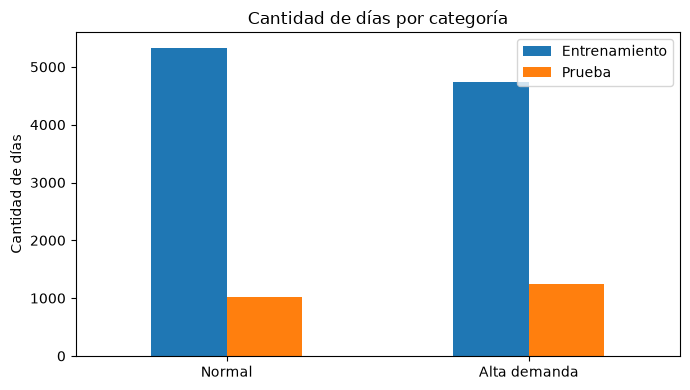

In [7]:
# Paso 7 · Casos por categoría

# Qué hacemos: contar cuántos días hay de cada categoría en entrenamiento y en prueba.
# Por qué: si una categoría tuviera muchos más casos que la otra, el modelo podría
# "acertar" casi siempre diciendo la mayoritaria sin aprender nada.

casos = pd.DataFrame({
    "Entrenamiento": y_ent.value_counts(),
    "Prueba": y_pru.value_counts(),
}).rename(index={0: "Normal", 1: "Alta demanda"})
print(casos)

# Gráfico de barras: una barra por categoría y conjunto
ax = casos.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_title("Cantidad de días por categoría")
ax.set_xlabel("")
ax.set_ylabel("Cantidad de días")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [8]:
# Proporción de días de alta demanda en prueba, por estación y tipo
(df[~es_entrenamiento]
 .groupby(["estacion", "tipo"])["alta_demanda"]
 .mean()
 .round(3)
 .rename("Proporción de alta demanda en prueba"))

estacion  tipo       
Norte     Basura         0.491
          Organicos      0.444
Sur       Basura         0.811
          Organicos      0.413
          Reciclables    0.581
Name: Proporción de alta demanda en prueba, dtype: float64

**Casos por categoría:**

| | Entrenamiento | Prueba |
| --- | --- | --- |
| Normal | 5.331 (53 %) | 1.018 (45 %) |
| Alta demanda | 4.741 (47 %) | 1.240 (55 %) |

En entrenamiento las clases quedan casi balanceadas por construcción. No es exactamente 50/50 porque muchos días tienen exactamente la cantidad de viajes de la mediana, y como la regla es **superar** la mediana, cuentan como normales.

En prueba la proporción se invierte: hay más días de alta demanda. El aumento se concentra en la basura de la estación Sur (81 % de días altos en prueba), porque los viajes crecieron con los años y el umbral quedó fijado en el período de entrenamiento. Es una limitación que hay que tener en cuenta al evaluar el modelo.

In [9]:
# Paso 8 · Bases de comparación

# Qué hacemos: calcular cuánto aciertan dos “modelos” que no aprenden nada.

# Por qué: un 70 % de aciertos no dice nada por sí solo. Puede ser muy bueno o muy malo según qué tan fácil sea el problema. Las bases de comparación son la vara: si el árbol no las supera, no aporta nada.

# Qué hacemos: medir cuánto aciertan dos reglas simples, sin aprendizaje.
# Por qué: sirven de vara para saber si el árbol realmente aporta algo.

# Base 1: predecir siempre la categoría más frecuente del entrenamiento ("Normal" = 0)
pred_mayoritaria = pd.Series(0, index=y_pru.index)

# Base 2: repetir la semana anterior. Un día es "alta" si la semana anterior,
# el mismo día, los viajes superaron el umbral de su estación y tipo
pred_sem_ant = (df.loc[~es_entrenamiento, "viajes_sem_ant"]
                > df.loc[~es_entrenamiento, "umbral_viajes"]).astype(int)

print(f"Siempre 'Normal':              {accuracy_score(y_pru, pred_mayoritaria):.1%}")
print(f"Repetir la semana anterior:    {accuracy_score(y_pru, pred_sem_ant):.1%}")

Siempre 'Normal':              45.1%
Repetir la semana anterior:    69.8%


Bases de comparación: predecir siempre “Normal” acierta el 45,1 % de los días de prueba. Repetir lo que pasó el mismo día de la semana anterior acierta el 69,8 %. Esta segunda regla es la vara real: es lo que haría un operador sin ningún modelo, por lo que el árbol solo aporta valor si la supera.

In [10]:
# Paso 9 · Elegir los parámetros con validación

# Qué hacemos: probar varias combinaciones de los dos parámetros que controlan el tamaño del árbol, y quedarnos con la que mejor predice datos que no vio.

# Los dos parámetros:

# max_depth (profundidad máxima): cuántas preguntas seguidas puede hacer el árbol. Más profundidad, reglas más detalladas, pero más riesgo de memorizar.
# min_samples_leaf (mínimo de días por hoja): cuántos días tiene que haber como mínimo en cada hoja. Evita reglas basadas en dos o tres casos sueltos.

# Por qué no elegirlos con los datos de prueba: si probamos combinaciones contra la prueba y elegimos la mejor
# la prueba deja de ser “datos que el modelo nunca vio”: la usamos para decidir. 
# Por eso separamos el último año del entrenamiento como validación. Es como un examen de práctica: elegimos con la validación, y la prueba queda reservada para el examen final.

# Qué hacemos: probar combinaciones de profundidad y mínimo de días por hoja,
# y elegir la que mejor predice un período que el árbol no vio.
# Por qué con validación y no con prueba: si elegimos mirando la prueba, deja de
# ser un examen justo. Separamos el último año del entrenamiento (desde el 1/12/2023)
# como "examen de práctica" y dejamos la prueba intacta para el final.

es_validacion = df.loc[es_entrenamiento, "fecha"] >= "2023-12-01"
X_aj, X_val = X_ent[~es_validacion], X_ent[es_validacion]
y_aj, y_val = y_ent[~es_validacion], y_ent[es_validacion]
print("Ajuste:", len(X_aj), "filas | Validación:", len(X_val), "filas")

resultados = []
# Dos bucles anidados: prueba cada profundidad con cada mínimo de días por hoja.
# None significa "sin límite de profundidad"
for profundidad in [3, 4, 5, 6, 8, 10, None]:
    for min_hoja in [1, 20, 50, 100]:
        # random_state=42 fija el azar interno, así el resultado se repite siempre igual
        prueba_arbol = DecisionTreeClassifier(max_depth=profundidad, min_samples_leaf=min_hoja, random_state=42)
        prueba_arbol.fit(X_aj, y_aj)          # aprende con el período de ajuste
        exactitud = accuracy_score(y_val, prueba_arbol.predict(X_val))  # se evalúa en validación
        resultados.append({"profundidad": profundidad, "min_hoja": min_hoja,
                           "exactitud_validacion": round(exactitud, 3),
                           "hojas": prueba_arbol.get_n_leaves()})

resultados = pd.DataFrame(resultados).sort_values("exactitud_validacion", ascending=False)
resultados.head(10)

Ajuste: 8774 filas | Validación: 1298 filas


,profundidad,min_hoja,exactitud_validacion,hojas
17,8.0,20,0.701,125
25,NaN,20,0.694,317
21,10.0,20,0.690,228
26,NaN,50,0.689,132
22,10.0,50,0.689,122
15,6.0,100,0.683,33
18,8.0,50,0.680,86
13,6.0,20,0.675,51
14,6.0,50,0.675,42
19,8.0,100,0.669,57


Elección de parámetros: se separó el último año del entrenamiento (del 1/12/2023 al 29/11/2024) como validación, para no usar los datos de prueba en ninguna decisión. Se probaron profundidades de 3 a 10 y sin límite, con un mínimo de 1, 20, 50 y 100 días por hoja. La mejor combinación fue profundidad 8 con al menos 20 días por hoja (70,1 % de exactitud en validación). Los árboles sin límite de profundidad y con hojas de un solo día rinden peor: memorizan casos particulares del entrenamiento (sobreajuste).

In [11]:
# Paso 10 · Entrenar el árbol final y predecir

# Qué hacemos: entrenar el árbol final con los parámetros elegidos, usando todo el entrenamiento (ajuste más validación), y predecir los días de prueba.

# Por qué ahora con todo el entrenamiento: la validación ya cumplió su función (elegir los parámetros). Para el modelo final conviene aprovechar todos los datos disponibles, incluido el año más reciente.

# Árbol con los parámetros elegidos en el Paso 9, entrenado con TODO el entrenamiento
arbol = DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=42)
arbol.fit(X_ent, y_ent)

# predict devuelve la categoría (0 o 1) para cada día de prueba
pred_arbol = arbol.predict(X_pru)

# predict_proba devuelve la probabilidad de cada categoría;
# [:, 1] se queda con la columna de "alta demanda".
# Es la proporción de días altos en la hoja a la que llegó cada caso
prob_arbol = arbol.predict_proba(X_pru)[:, 1]

print("Hojas del árbol:", arbol.get_n_leaves())
print(f"Árbol de decisión:             {accuracy_score(y_pru, pred_arbol):.1%}")
print(f"Repetir la semana anterior:    {accuracy_score(y_pru, pred_sem_ant):.1%}")
print(f"Siempre 'Normal':              {accuracy_score(y_pru, pred_mayoritaria):.1%}")

Hojas del árbol: 115
Árbol de decisión:             70.4%
Repetir la semana anterior:    69.8%
Siempre 'Normal':              45.1%


In [12]:
# Paso 11 · Ejemplos de valores reales y predichos

# Por qué: la consigna pide mostrar ejemplos para interpretar aciertos y errores.

# Tabla con los datos de prueba, la categoría real, la predicha y la probabilidad
ejemplos = df.loc[~es_entrenamiento, ["fecha", "estacion", "tipo", "viajes_sem_ant",
                                       "umbral_viajes", "viajes", "alta_demanda"]].copy()
ejemplos["predicho"] = pred_arbol
ejemplos["prob_alta"] = prob_arbol.round(2)
ejemplos["acierto"] = ejemplos["alta_demanda"] == ejemplos["predicho"]

# Un día común completo: las cinco combinaciones del martes 11/03/2025
ejemplos[ejemplos["fecha"] == "2025-03-11"]

,fecha,estacion,tipo,viajes_sem_ant,umbral_viajes,viajes,alta_demanda,predicho,prob_alta,acierto
10403,2025-03-11,Norte,Basura,27,26.0,28,1,1,0.66,True
10404,2025-03-11,Norte,Organicos,5,6.0,4,0,0,0.49,True
10405,2025-03-11,Sur,Basura,94,85.0,96,1,1,0.75,True
10406,2025-03-11,Sur,Organicos,53,52.0,55,1,0,0.42,False
10407,2025-03-11,Sur,Reciclables,98,86.0,94,1,1,1.00,True


In [13]:
# Una muestra de errores (random_state fija cuáles salen, para que siempre sean los mismos)
ejemplos[~ejemplos["acierto"]].sample(8, random_state=42).sort_values("fecha")

,fecha,estacion,tipo,viajes_sem_ant,umbral_viajes,viajes,alta_demanda,predicho,prob_alta,acierto
10619,2025-05-09,Norte,Organicos,6,6.0,5,0,1,0.51,False
10768,2025-06-20,Norte,Basura,27,26.0,31,1,0,0.48,False
10981,2025-08-20,Sur,Basura,86,85.0,87,1,0,0.30,False
11095,2025-09-22,Norte,Organicos,10,6.0,6,0,1,0.75,False
11266,2025-11-07,Sur,Basura,89,85.0,85,0,1,0.85,False
11274,2025-11-11,Norte,Basura,28,26.0,25,0,1,0.61,False
11710,2026-03-17,Norte,Basura,28,26.0,19,0,1,0.66,False
11877,2026-05-01,Sur,Basura,89,85.0,85,0,1,0.57,False


Ejemplos: el martes 11/03/2025 el árbol acierta 4 de las 5 combinaciones. Falla en orgánicos de la estación Sur, donde hubo 55 viajes con un umbral de 52: le asignó un 42 % de probabilidad de alta demanda. La mayoría de los errores son casos al borde del umbral, donde uno o dos viajes de diferencia cambian la categoría. Por eso, la probabilidad que entrega el árbol es más informativa que la categoría sola: un 51 % y un 95 % indican situaciones muy distintas.

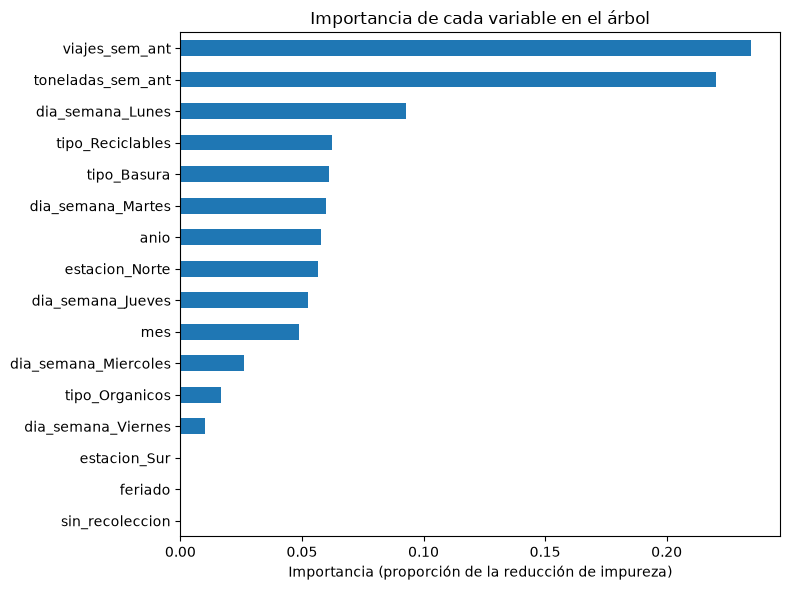

viajes_sem_ant       0.235
toneladas_sem_ant    0.220
dia_semana_Lunes     0.093
tipo_Reciclables     0.063
tipo_Basura          0.061
dia_semana_Martes    0.060
dtype: float64

In [14]:
# Paso 12 · Qué aprendió el árbol
# 12a · Importancia de las variables

# feature_importances_ indica cuánto contribuyó cada variable a reducir la impureza
# (Gini) en todo el árbol. Suman 1 entre todas
importancia = pd.Series(arbol.feature_importances_, index=X.columns).sort_values(ascending=True)

ax = importancia.plot(kind="barh", figsize=(8, 6))
ax.set_title("Importancia de cada variable en el árbol")
ax.set_xlabel("Importancia (proporción de la reducción de impureza)")
plt.tight_layout()
plt.show()

importancia.sort_values(ascending=False).round(3).head(6)

Exactitud del árbol de lectura en prueba: 64.3%


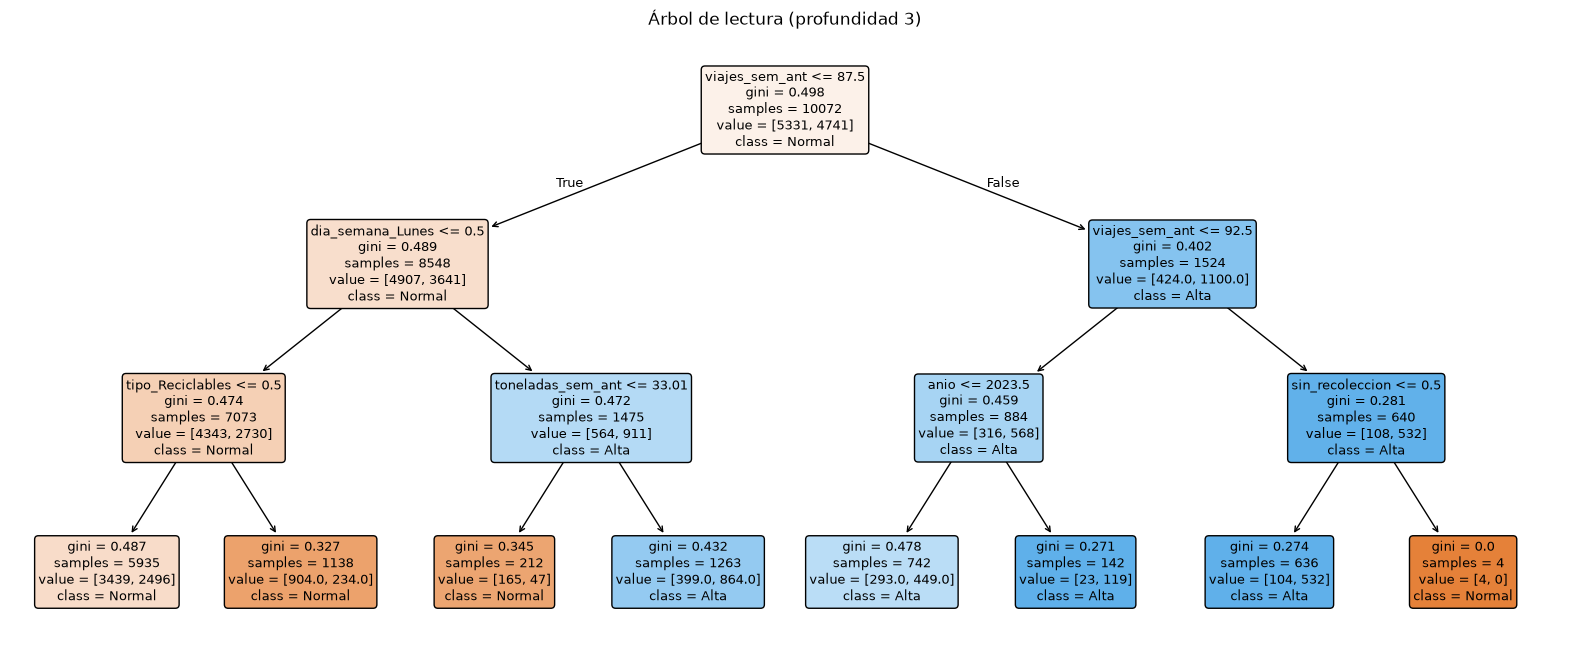

In [15]:
# 12b · Árbol de lectura (profundidad 3)

# Por qué un árbol aparte: el árbol final tiene 115 hojas y dibujado no se puede leer. 
# Para mostrar cómo razona, entrenamos uno de solo 3 niveles, que es legible. 
# Es una versión simplificada para interpretar, no el modelo que usamos para predecir.

# Árbol chico, solo para leer sus reglas. NO es el modelo final
arbol_lectura = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol_lectura.fit(X_ent, y_ent)
print(f"Exactitud del árbol de lectura en prueba: {accuracy_score(y_pru, arbol_lectura.predict(X_pru)):.1%}")

plt.figure(figsize=(20, 8))
# filled colorea cada nodo según la categoría mayoritaria (más intenso = más "puro")
plot_tree(arbol_lectura, feature_names=X.columns, class_names=["Normal", "Alta"],
          filled=True, rounded=True, fontsize=9)
plt.title("Árbol de lectura (profundidad 3)")
plt.show()

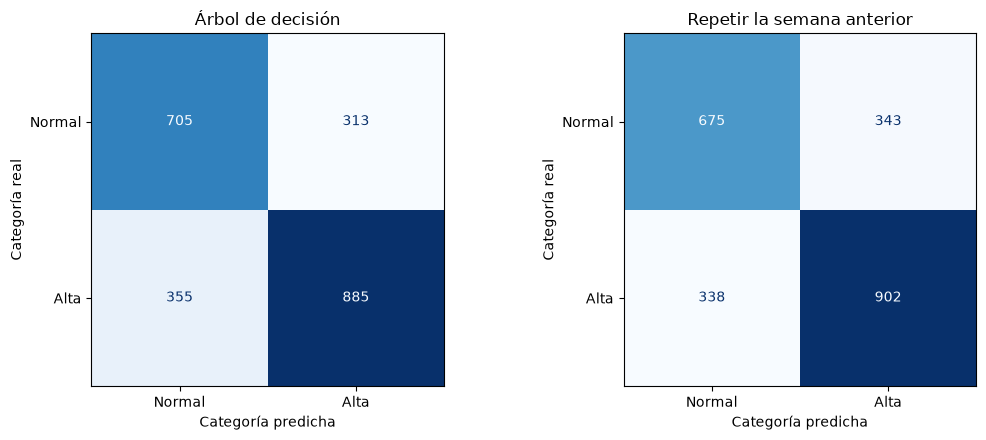

In [16]:
# Paso 13 · Matriz de confusión

# Qué hacemos: separar los aciertos y los errores en cuatro casillas, y comparar el árbol con la regla de repetir la semana anterior.

# Por qué: la exactitud mezcla dos errores que en la práctica no valen lo mismo. La matriz los separa: cuántas falsas alarmas hubo y cuántos días altos no se anticiparon.

# Qué hacemos: contar, para cada categoría real, qué predijo el modelo.
# Por qué: la exactitud mezcla dos errores distintos (falsa alarma y día alto no anticipado),
# y para UrbanRec no tienen la misma consecuencia.

# Dos gráficos lado a lado: el árbol y la regla "repetir la semana anterior"
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for eje, pred, titulo in [(ejes[0], pred_arbol, "Árbol de decisión"),
                          (ejes[1], pred_sem_ant, "Repetir la semana anterior")]:
    # from_predictions arma la matriz a partir de los valores reales y los predichos
    ConfusionMatrixDisplay.from_predictions(y_pru, pred, display_labels=["Normal", "Alta"],
                                            cmap="Blues", colorbar=False, ax=eje)
    eje.set_title(titulo)
    eje.set_xlabel("Categoría predicha")
    eje.set_ylabel("Categoría real")
plt.tight_layout()
plt.show()

In [17]:
# Paso 14 · Métricas por categoría

# classification_report calcula precisión, recall y F1 para cada categoría
print(classification_report(y_pru, pred_arbol, target_names=["Normal", "Alta demanda"], digits=3))

              precision    recall  f1-score   support

      Normal      0.665     0.693     0.679      1018
Alta demanda      0.739     0.714     0.726      1240

    accuracy                          0.704      2258
   macro avg      0.702     0.703     0.702      2258
weighted avg      0.706     0.704     0.705      2258



In [18]:
# Para comparar modelos en una sola tabla, creamos una función que podemos reutilizar.
# Función que calcula las cuatro métricas sobre la categoría "alta demanda".
# Definirla una vez evita repetir las mismas cuatro líneas para cada modelo
def metricas(y_real, y_pred):
    return {"Recall (alta)": recall_score(y_real, y_pred),
            "Precisión (alta)": precision_score(y_real, y_pred),
            "F1 (alta)": f1_score(y_real, y_pred),
            "Exactitud": accuracy_score(y_real, y_pred)}

pd.DataFrame({"Árbol": metricas(y_pru, pred_arbol),
              "Repetir la semana anterior": metricas(y_pru, pred_sem_ant)}).round(3)

,Árbol,Repetir la semana anterior
Recall (alta),0.714,0.727
Precisión (alta),0.739,0.724
F1 (alta),0.726,0.726
Exactitud,0.704,0.698


Métrica elegida: recall de la categoría “alta demanda”. Para el operador, no anticipar un día de alta demanda implica salir con camiones de menos, recorridos incompletos y reclamos de vecinos; una falsa alarma implica un camión o un turno extra que no hacía falta. El primer error es más grave, por lo que se prioriza el recall. La precisión se informa como control, porque un modelo que alertara todos los días tendría recall perfecto sin aportar información.

Con el criterio estándar (predecir “alta” si la probabilidad supera 0,5), el árbol anticipa el 71,4 % de los días altos, por debajo de la regla de repetir la semana anterior (72,7 %).

In [19]:
# Paso 15 · Ajustar el umbral de decisión

# Qué hacemos: cambiar a partir de qué probabilidad el árbol dice “alta”.

# Por qué: por defecto, el árbol dice “alta” si la probabilidad de la hoja supera 0,5. 
# Pero si un día alto no anticipado es más grave que una falsa alarma, conviene dar la alerta antes, por ejemplo desde 0,4.
# Así se escapan menos días altos, a cambio de más falsas alarmas.

# Qué hacemos: elegir desde qué probabilidad el árbol da la alerta de "alta demanda".
# Por qué: como no anticipar un día alto es el error más grave, conviene alertar antes de 0,5.
# Se elige con la validación (último año del entrenamiento), no con la prueba.

# Mismo árbol del Paso 10, pero entrenado solo con el período de ajuste
arbol_val = DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=42)
arbol_val.fit(X_aj, y_aj)
prob_val = arbol_val.predict_proba(X_val)[:, 1]

filas = []
for umbral in [0.30, 0.35, 0.40, 0.45, 0.50]:
    # "alta" si la probabilidad supera el umbral
    pred_val = (prob_val > umbral).astype(int)
    # ** desarma el diccionario de métricas dentro de la fila
    filas.append({"umbral": umbral, **metricas(y_val, pred_val)})
pd.DataFrame(filas).round(3)

,umbral,Recall (alta),Precisión (alta),F1 (alta),Exactitud
0,0.30,0.830,0.722,0.772,0.718
1,0.35,0.814,0.724,0.766,0.714
2,0.40,0.774,0.747,0.760,0.719
3,0.45,0.736,0.748,0.742,0.706
4,0.50,0.683,0.772,0.724,0.701


In [20]:
# Umbral elegido con la validación
UMBRAL = 0.40

# prob_arbol viene del Paso 10: probabilidad de "alta" para cada día de prueba
pred_arbol_04 = (prob_arbol > UMBRAL).astype(int)

pd.DataFrame({"Árbol, umbral 0,5": metricas(y_pru, pred_arbol),
              "Árbol, umbral 0,4": metricas(y_pru, pred_arbol_04),
              "Repetir la semana anterior": metricas(y_pru, pred_sem_ant)}).round(3)

,"Árbol, umbral 0,5","Árbol, umbral 0,4",Repetir la semana anterior
Recall (alta),0.714,0.785,0.727
Precisión (alta),0.739,0.699,0.724
F1 (alta),0.726,0.739,0.726
Exactitud,0.704,0.696,0.698


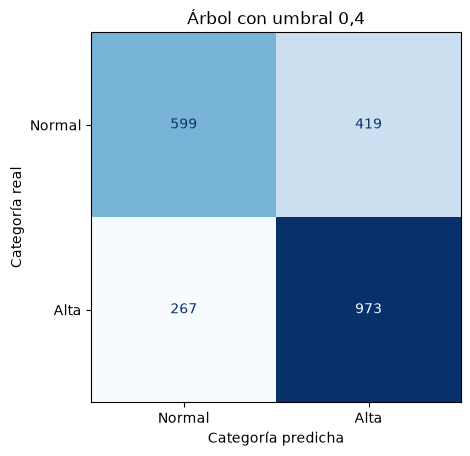

In [21]:
# Matriz de confusión del árbol con el umbral elegido
ConfusionMatrixDisplay.from_predictions(y_pru, pred_arbol_04, display_labels=["Normal", "Alta"],
                                        cmap="Blues", colorbar=False)
plt.title("Árbol con umbral 0,4")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.show()

Umbral de decisión: se eligió con la validación un umbral de 0,4 en lugar de 0,5: sube el recall de 68 % a 77 % con una pérdida mínima de precisión (de 77 % a 75 %). En la prueba, el árbol con umbral 0,4 anticipa el 78,5 % de los días de alta demanda (973 de 1.240), contra el 72,7 % de la regla de repetir la semana anterior (902). A cambio, genera 419 falsas alarmas contra 343. Para la operación es un intercambio conveniente: se cambian días sin camiones suficientes por días con un camión de reserva. Esta posibilidad de ajuste es una ventaja propia del árbol, porque entrega una probabilidad; la regla simple no la tiene.

In [22]:
# Paso 16 · Dónde se equivoca

# Qué hacemos: separar los errores según distintas condiciones.

# Por qué: la consigna pide interpretar qué confunde el modelo y por qué. Saber dónde falla dice cuándo confiar en él y cuándo no.

# Tabla con los datos de prueba, la categoría real y la predicha con umbral 0,4
errores = df.loc[~es_entrenamiento, ["fecha", "estacion", "tipo", "dia_semana", "feriado",
                                     "sin_recoleccion", "viajes", "umbral_viajes", "alta_demanda"]].copy()
errores["predicho"] = pred_arbol_04
errores["acierto"] = errores["predicho"] == errores["alta_demanda"]

# 16a · Distancia entre los viajes reales y el umbral (abs = valor absoluto, sin signo)
errores["distancia"] = (errores["viajes"] - errores["umbral_viajes"]).abs()

# pd.cut agrupa los valores en rangos
errores["cercania"] = pd.cut(errores["distancia"], bins=[-0.1, 2, 5, 10, 1000],
                             labels=["0 a 2 viajes", "3 a 5 viajes", "6 a 10 viajes", "más de 10"])

# El promedio de una columna True/False es la proporción de True: la exactitud
errores.groupby("cercania", observed=True)["acierto"].agg(dias="size", exactitud="mean").round(3)

,dias,exactitud
cercania,,
0 a 2 viajes,864,0.567
3 a 5 viajes,654,0.711
6 a 10 viajes,480,0.812
más de 10,260,0.873


In [23]:
# 16b · Exactitud por estación y tipo de residuo
errores.groupby(["estacion", "tipo"])["acierto"].agg(dias="size", exactitud="mean").round(3)

dias  exactitud
estacion tipo                        
Norte    Basura        448      0.679
         Organicos     441      0.635
Sur      Basura        460      0.735
         Organicos     458      0.648
         Reciclables   451      0.783

In [24]:
# Exactitud por día de la semana
errores.groupby("dia_semana")["acierto"].mean().round(3).rename("exactitud")

dia_semana
Jueves       0.689
Lunes        0.771
Martes       0.720
Miercoles    0.600
Viernes      0.698
Name: exactitud, dtype: float64

In [25]:
# 16c · ¿Qué hizo el árbol en los días sin recolección?
errores[errores["sin_recoleccion"] == 1][["fecha", "estacion", "tipo", "viajes", "alta_demanda", "predicho"]]

,fecha,estacion,tipo,viajes,alta_demanda,predicho
10154,2024-12-25,Sur,Basura,2,0,0
10155,2024-12-25,Sur,Organicos,4,0,0
10176,2025-01-01,Sur,Basura,2,0,0
10177,2025-01-01,Sur,Organicos,2,0,0
11334,2025-11-27,Sur,Basura,4,0,1
11335,2025-11-27,Sur,Organicos,4,0,1
11428,2025-12-25,Sur,Basura,3,0,0
11429,2025-12-25,Sur,Organicos,2,0,1
11450,2026-01-01,Sur,Basura,2,0,0
11451,2026-01-01,Sur,Organicos,2,0,0


Análisis de errores:

La cercanía al umbral es la principal causa de error. Cuando los viajes quedaron a 2 o menos del umbral, el árbol acierta el 56,7 % de los días; cuando la diferencia supera los 10 viajes, el 87,3 %. El 38 % de los días de prueba están en la primera situación: un viaje de diferencia cambia la categoría, y ninguna variable disponible lo puede anticipar.
Por combinación: el mejor resultado es en reciclables de la estación Sur (78,3 %) y el peor en orgánicos de la Norte (63,5 %), cuyo umbral de 6 viajes hace que un solo viaje cambie la categoría.
Por día: el lunes es el día más predecible (77,1 %) y el miércoles el menos (60,0 %).
Días sin recolección: de 10 casos en prueba, el árbol falla en 3 (Acción de Gracias y Navidad de 2025). Con solo unos 20 ejemplos en el entrenamiento, el árbol no usa esa variable en todas sus ramas. En un sistema real convendría una regla fija para esos días.

Conclusión del modelo de clasificación. Con el umbral ajustado a 0,4, el árbol de decisión anticipa el 78,5 % de los días de alta demanda, contra el 72,7 % de repetir lo ocurrido la semana anterior, a cambio de más falsas alarmas. Su exactitud general (69,6 %) es similar a la de esa regla, por lo que su aporte no está en acertar más días en total, sino en tres cosas: permite elegir cuánto arriesgar ajustando el umbral, entrega una probabilidad que indica qué tan segura es cada alerta, y produce reglas que se pueden explicar al operador.

Limitaciones: la principal es la definición de la categoría por la mediana, que deja muchos días al borde del umbral; una categoría con un margen (por ejemplo, alta demanda solo si se supera la mediana en más de 5 viajes) sería más útil para la operación. Además, el umbral quedó fijo en el período de entrenamiento mientras los viajes crecían, y los días sin recolección tienen pocos ejemplos para aprender.

## Paso 17 · Conclusión de la evaluación

**Métrica elegida: recall de la clase "alta demanda".** Para UrbanRec, el error más grave es no anticipar un día alto, porque la empresa sale con menos camiones de los necesarios. Una falsa alarma deja camiones sin usar, que es un costo menor. La precisión se usa como control, para que el modelo no marque alertas todos los días.

**Resultado.** Con el umbral de 0,4, elegido con el último año del entrenamiento y no con la prueba, el árbol anticipa el **78,5 % de los días altos** (973 de 1.240). La regla "repetir la semana anterior" anticipa el 72,7 % (902). A cambio, el árbol da más falsas alarmas: 419 contra 343. En total se equivoca en 686 de los 2.258 días de prueba: 267 días altos que no anticipó y 419 falsas alarmas.

**Dónde se equivoca**

- **Cerca del umbral.** Cuando los viajes del día quedan a 2 viajes o menos de la mediana, acierta solo el 56,7 %. Cuando quedan a más de 10, acierta el 87,3 %. El 55 % de los errores ocurre en días a 2 viajes o menos del umbral, y el 82 % en días a 5 viajes o menos. La mayoría de los errores son días "en el límite", donde equivocarse cuesta uno o dos camiones, no una jornada mal planificada.
- **Por estación y tipo.** Va mejor en reciclables de la Sur (78,3 %) y en basura de la Sur (73,5 %). Va peor en orgánicos, tanto en la Norte (63,5 %) como en la Sur (64,8 %). Probablemente se deba a que los orgánicos dependen más de la época del año y del clima, que el modelo no conoce.
- **Por día de la semana.** El lunes es el día con más aciertos (77,1 %) y el miércoles el que menos (60,0 %). Con estos datos no tenemos una explicación verificada para esa diferencia.
- **Días sin recolección.** En prueba hay 10 casos (Navidad, Año Nuevo y Acción de Gracias, todos de la estación Sur). Clasificó bien 7 y marcó como alta demanda 3 días en que casi no hubo viajes: los dos de Acción de Gracias 2025 y orgánicos en Navidad 2025. Una causa posible es que hay muy pocos días así en el entrenamiento y que en la temporada 2023-24 sí hubo recolección parcial. Para el uso real, el sistema debería anular la alerta en esas fechas, porque se conocen de antemano.

**Lectura honesta.** En exactitud, el árbol apenas supera a la regla de la semana anterior. Lo que aporta es anticipar más días altos y explicar con reglas legibles por qué marca una alerta. Sus errores se concentran en días donde la diferencia con lo normal es mínima.